In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve)

In [2]:
# CARGAR MODELOS

reg_log_diab_class_weight = joblib.load("../models/reg_log_diab_class_weight.joblib")
reg_log_diab = joblib.load("../models/reg_log_diab.joblib")
reg_log_diab_smote = joblib.load("../models/reg_log_diab_smote.joblib")

In [3]:
# CARGAR LOS DATOS DE TEST 

X_test_diab = pd.read_csv("../data/processed/X_test_diab_df.csv")
y_test_diab = pd.read_csv("../data/processed/y_test_diab.csv")

# REGRESIÓN LOGÍSTICA

INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)
              precision    recall  f1-score   support

           0     0.9687    0.7143    0.8223      3773
           1     0.2256    0.7830    0.3503       401

    accuracy                         0.7209      4174
   macro avg     0.5972    0.7487    0.5863      4174
weighted avg     0.8973    0.7209    0.7769      4174

ROC-AUC Score: 0.8146


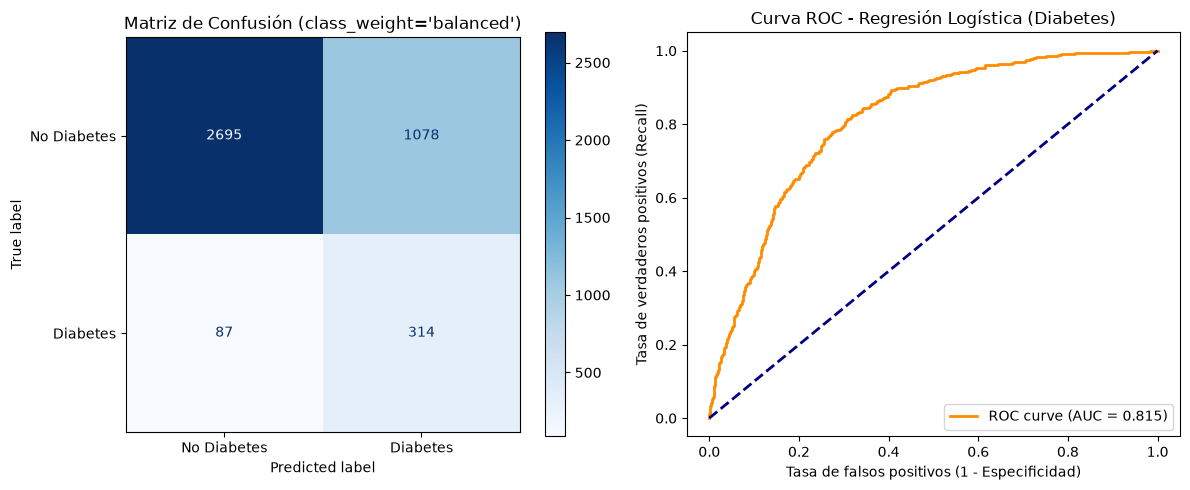

In [4]:
# ======================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS 
# ======================================================

# Predicciones 
y_pred_diab = reg_log_diab_class_weight.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - HIPERTENSIÓN (Balanceado)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (class_weight='balanced')")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)
              precision    recall  f1-score   support

           0     0.9743    0.6721    0.7955      3773
           1     0.2126    0.8329    0.3387       401

    accuracy                         0.6876      4174
   macro avg     0.5934    0.7525    0.5671      4174
weighted avg     0.9011    0.6876    0.7516      4174

ROC-AUC Score: 0.8128


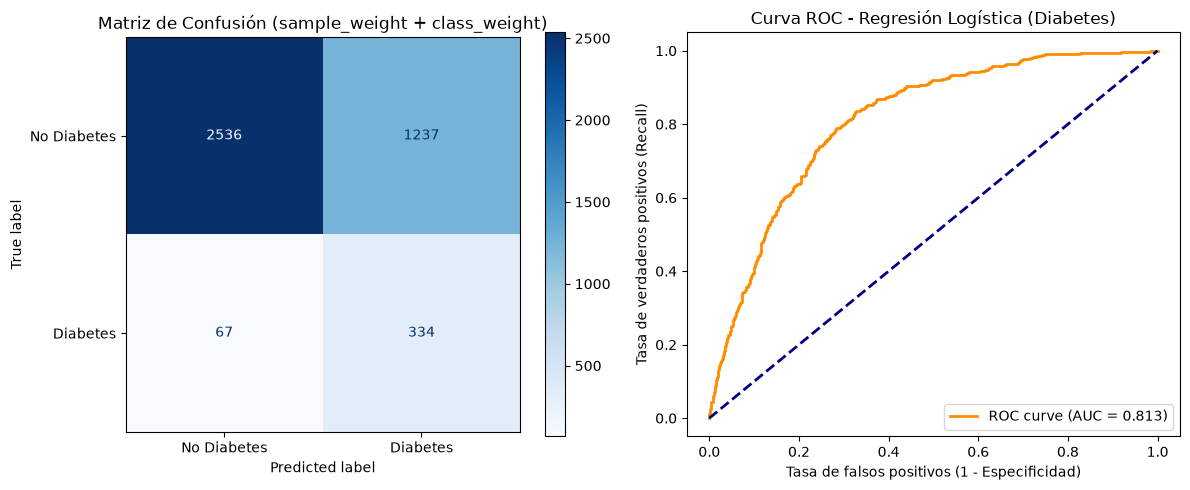

In [5]:
# =======================================================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON PESOS BALANCEADOS Y FACTOR ADULTO
# =======================================================================

# Predicciones 
y_pred_diab = reg_log_diab.predict(X_test_diab)
y_pred_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# Evaluación de métricas
print("INFORME DE CLASIFICACIÓN - DIABETES (Balanceado + Factor Adulto)")
print(classification_report(y_test_diab, y_pred_diab, digits=4))

auc_diab = roc_auc_score(y_test_diab, y_pred_proba_diab)
print(f"ROC-AUC Score: {auc_diab:.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (sample_weight + class_weight)")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_diab, y_pred_proba_diab)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_diab:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


In [6]:
# 1. Obtenemos las probabilidades predichas (ya entrenado con 'balanced' + sample_weight)
y_proba_diab = reg_log_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probamos distintos umbrales (ejemplo: 0.40, 0.45, 0.50, 0.55)
umbrales = [0.35, 0.40, 0.45, 0.50, 0.55]

for u in umbrales:
    y_pred_u = (y_proba_diab >= u).astype(int)
    report = classification_report(
        y_test_diab, y_pred_u, digits=4, output_dict=True
    )

    rec = report["1"]["recall"]
    prec = report["1"]["precision"]
    f1 = report["1"]["f1-score"]

    print(
        f"Umbral {u:.2f} -> Recall Diabetes: {rec*100:.2f}% | Precisión Diabetes: {prec*100:.2f}% | F1: {f1:.4f}"
    )

Umbral 0.35 -> Recall Diabetes: 90.52% | Precisión Diabetes: 17.46% | F1: 0.2927
Umbral 0.40 -> Recall Diabetes: 88.03% | Precisión Diabetes: 18.57% | F1: 0.3067
Umbral 0.45 -> Recall Diabetes: 85.29% | Precisión Diabetes: 19.88% | F1: 0.3225
Umbral 0.50 -> Recall Diabetes: 83.29% | Precisión Diabetes: 21.26% | F1: 0.3387
Umbral 0.55 -> Recall Diabetes: 79.30% | Precisión Diabetes: 22.35% | F1: 0.3487


DIABETES CON SMOTE
              precision    recall  f1-score   support

           0     0.9667    0.7315    0.8328      3773
           1     0.2320    0.7631    0.3558       401

    accuracy                         0.7345      4174
   macro avg     0.5994    0.7473    0.5943      4174
weighted avg     0.8961    0.7345    0.7870      4174

ROC-AUC Score: 0.8132


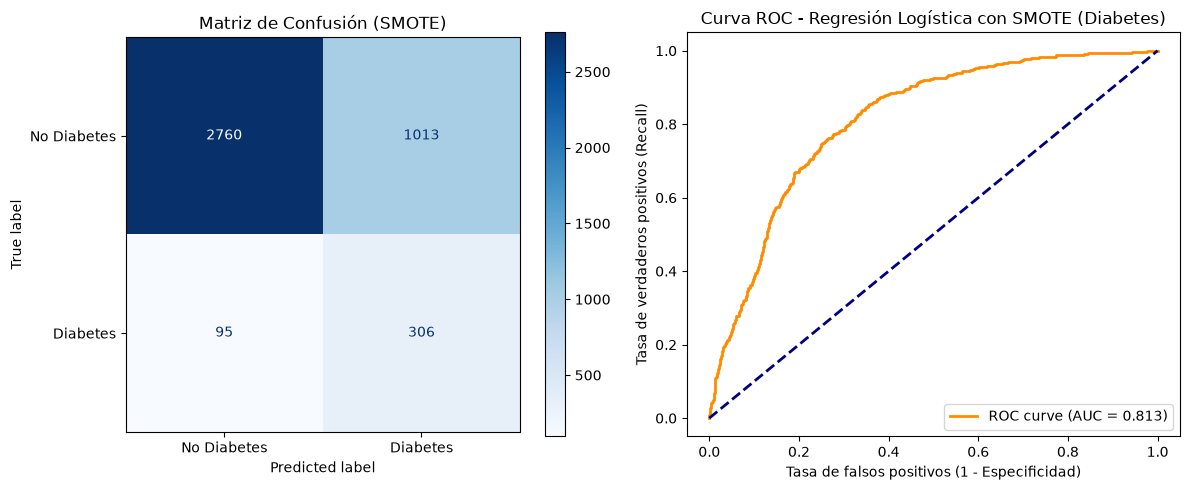

In [7]:
# ==========================================
# EVALUACIÓN REGRESIÓN LOGÍSTICA CON SMOTE
# ==========================================

# Se evalua en el X_test original 
y_pred_diab_smote = reg_log_diab_smote.predict(X_test_diab)
y_proba_diab_smote = reg_log_diab_smote.predict_proba(X_test_diab)[:, 1]

print("DIABETES CON SMOTE")
print(classification_report(y_test_diab, y_pred_diab_smote, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test_diab, y_proba_diab_smote):.4f}")

# Matriz de confusión y curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test_diab, y_pred_diab_smote)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión (SMOTE)")

# Curva ROC
fpr_smote, tpr_smote, _ = roc_curve(y_test_diab, y_proba_diab_smote)
auc_smote = roc_auc_score(y_test_diab, y_proba_diab_smote)
axes[1].plot(fpr_smote, tpr_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_smote:.3f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Regresión Logística con SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### CONCLUSIONES

El modelo seleccionado como Baseline es el de class_weight='balanced' y FACTORADULTO, sobre el cual se aplicó una optimización de umbral de decisión en 0.40. Esta combinación maximiza la capacidad de detección temprana, alcanzando una Sensibilidad(Recall) del 88.03% en el grupo de riesgo de diabetes. Fue necesario bajar el umbral para no dejar pasar tantos enfermos. 


# EVALUACIÓN MODELO RANDOM FOREST 

In [18]:
# Cargar modelo Random Forest

rf_diab_class_weight = joblib.load("../models/random_forest_diab_class_weight.joblib")
rf_diab = joblib.load("../models/random_forest_diab.joblib")
rf_smote_diab = joblib.load("../models/rf_smote_diabetes.joblib")
brf_diabetes = joblib.load("../models/balanced_random_forest_diab.joblib")
rf_subsample = joblib.load("../models/subsample_random_forest_diab.joblib")
brf_opt= joblib.load("../models/brf_diab_opt.joblib")
brf_diab_optimo = joblib.load("../models/balanced_rf_diab_optimo.joblib")

INFORME DE CLASIFICACIÓN - RF class_weight DIABETES
              precision    recall  f1-score   support

           0     0.9183    0.9647    0.9409      3773
           1     0.3667    0.1920    0.2520       401

    accuracy                         0.8905      4174
   macro avg     0.6425    0.5784    0.5965      4174
weighted avg     0.8653    0.8905    0.8748      4174

ROC-AUC Score: 0.8037


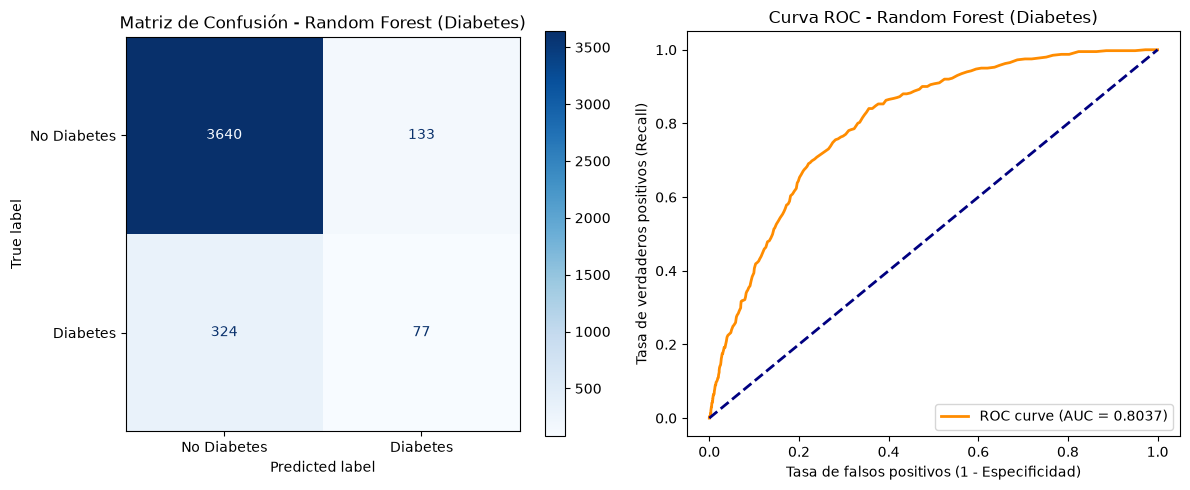

In [9]:
# ========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') - DIABETES
# ========================================================

# Predicciones 
y_pred_rf_diab_class_weight = rf_diab_class_weight.predict(X_test_diab)
y_proba_rf_diab_class_weight = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight DIABETES")
print(classification_report(y_test_diab, y_pred_rf_diab_class_weight, digits=4))

# ROC-AUC 
auc_rf_diab_class_weight = roc_auc_score(y_test_diab, y_proba_rf_diab_class_weight)
print(f"ROC-AUC Score: {auc_rf_diab_class_weight:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (Diabetes)")

# Curva ROC
fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, _ = roc_curve(y_test_diab, y_proba_rf_diab_class_weight)
axes[1].plot(fpr_rf_diab_class_weight, tpr_rf_diab_class_weight, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab_class_weight:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [10]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab_class_weight.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,92.02%,15.48%,0.2650,32
1,0.15,86.53%,18.65%,0.3068,54
2,0.20,78.30%,20.84%,0.3291,87
3,0.25,70.82%,23.91%,0.3575,117
4,0.30,60.85%,25.82%,0.3626,157
5,0.50,19.45%,36.79%,0.2545,323


INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight
              precision    recall  f1-score   support

           0     0.9244    0.9372    0.9308      3773
           1     0.3209    0.2793    0.2987       401

    accuracy                         0.8740      4174
   macro avg     0.6227    0.6082    0.6147      4174
weighted avg     0.8665    0.8740    0.8700      4174

ROC-AUC Score: 0.8025


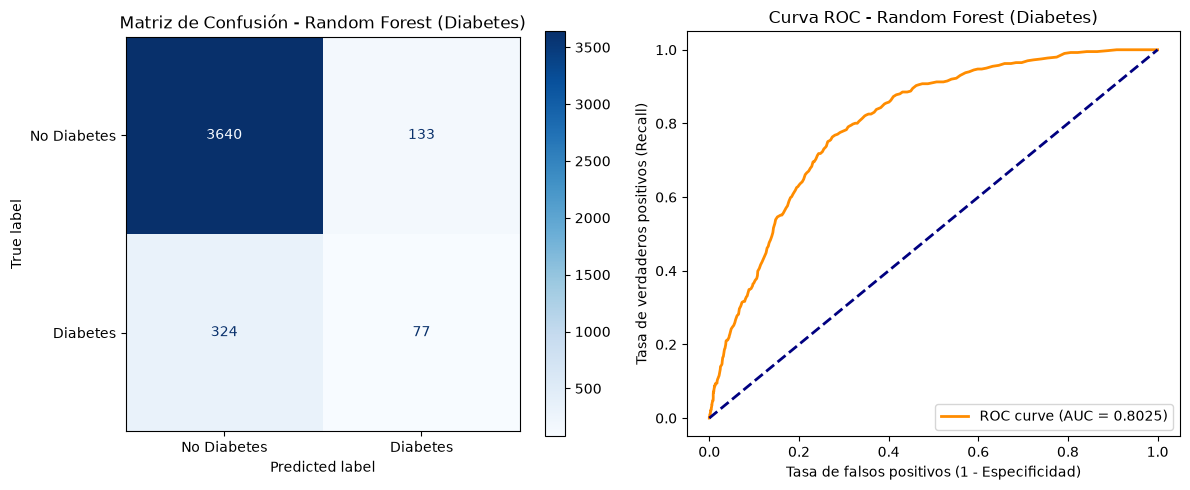

In [11]:
# ==========================================================
# EVALUACIÓN RANDOM FOREST ('class_weight') Y 'sample_weight' 
# ==========================================================

# Predicciones 
y_pred_rf_diab= rf_diab.predict(X_test_diab)
y_proba_rf_diab = rf_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF class_weight y sample_weight")
print(classification_report(y_test_diab, y_pred_rf_diab, digits=4))

# ROC-AUC 
auc_rf_diab = roc_auc_score(y_test_diab, y_proba_rf_diab)
print(f"ROC-AUC Score: {auc_rf_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_diab_class_weight = confusion_matrix(y_test_diab, y_pred_rf_diab_class_weight)
disp_rf_diab_class_weight = ConfusionMatrixDisplay(confusion_matrix=cm_rf_diab_class_weight, display_labels=["No Diabetes", "Diabetes"])
disp_rf_diab_class_weight.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (Diabetes)")

# Curva ROC
fpr_rf_diab, tpr_rf_diab, _ = roc_curve(y_test_diab, y_proba_rf_diab)
axes[1].plot(fpr_rf_diab, tpr_rf_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [12]:
# MOVER UMBRAL DE DECISIÓN 

# 1. Obtener probabilidades para la clase Diabetes (1)
y_proba_rf_db = rf_diab.predict_proba(X_test_diab)[:, 1]

# 2. Probar umbrales más bajos para forzar la detección
umbrales = [0.10, 0.15, 0.20, 0.25, 0.30, 0.50]
res = []

for u in umbrales:
    y_pred_u = (y_proba_rf_db >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    res.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Enfermos no detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_res = pd.DataFrame(res)
display(df_res)

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Enfermos no detectados)
0,0.10,92.27%,15.11%,0.2596,30
1,0.15,88.53%,17.73%,0.2955,45
2,0.20,82.54%,19.56%,0.3163,70
3,0.25,77.56%,22.03%,0.3431,90
4,0.30,69.58%,24.03%,0.3572,122
5,0.50,28.18%,31.48%,0.2974,288


INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE
              precision    recall  f1-score   support

           0     0.9152    0.9666    0.9402      3773
           1     0.3333    0.1571    0.2136       401

    accuracy                         0.8888      4174
   macro avg     0.6243    0.5619    0.5769      4174
weighted avg     0.8593    0.8888    0.8704      4174

ROC-AUC Score: 0.7991


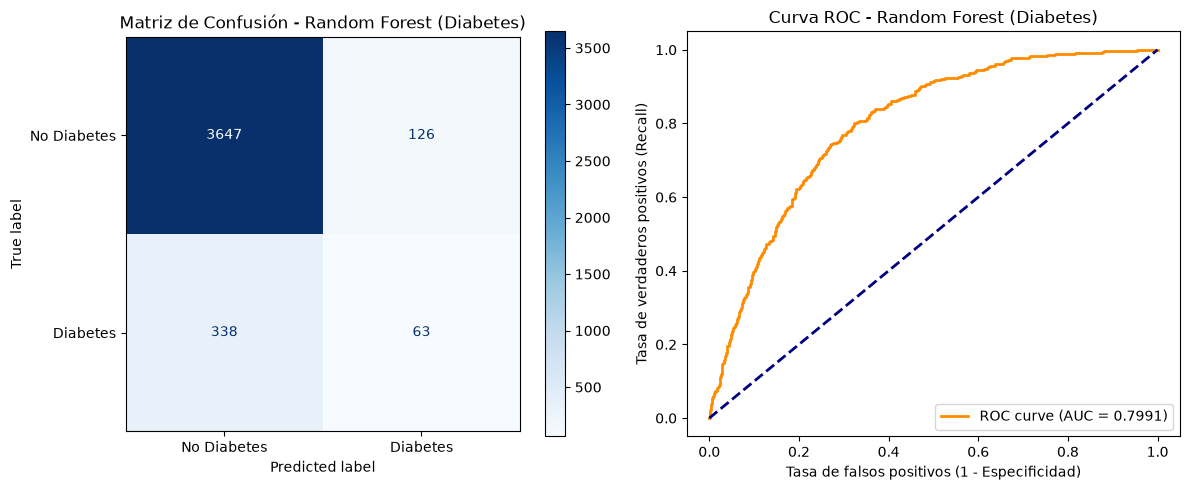

In [13]:
# ===============================
# EVALUACIÓN RANDOM FOREST SMOTE 
# ===============================

# Predicciones 
y_pred_rf_smote_diab = rf_smote_diab.predict(X_test_diab)
y_proba_rf_smote_diab = rf_smote_diab.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RANDOM FOREST C/ SMOTE")
print(classification_report(y_test_diab, y_pred_rf_smote_diab, digits=4))

# ROC-AUC 
auc_rf_smote_diab = roc_auc_score(y_test_diab, y_proba_rf_smote_diab)
print(f"ROC-AUC Score: {auc_rf_smote_diab:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_smote_diab = confusion_matrix(y_test_diab, y_pred_rf_smote_diab)
disp_rf_smote_diab = ConfusionMatrixDisplay(confusion_matrix=cm_rf_smote_diab, display_labels=["No Diabetes", "Diabetes"])
disp_rf_smote_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (Diabetes)")

# Curva ROC
fpr_rf_smote_diab, tpr_rf_smote_diab, _ = roc_curve(y_test_diab, y_proba_rf_smote_diab)
axes[1].plot(fpr_rf_smote_diab, tpr_rf_smote_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_smote_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS
              precision    recall  f1-score   support

           0     0.9504    0.7970    0.8669      3773
           1     0.2416    0.6085    0.3459       401

    accuracy                         0.7789      4174
   macro avg     0.5960    0.7027    0.6064      4174
weighted avg     0.8823    0.7789    0.8169      4174

ROC-AUC Score: 0.7955


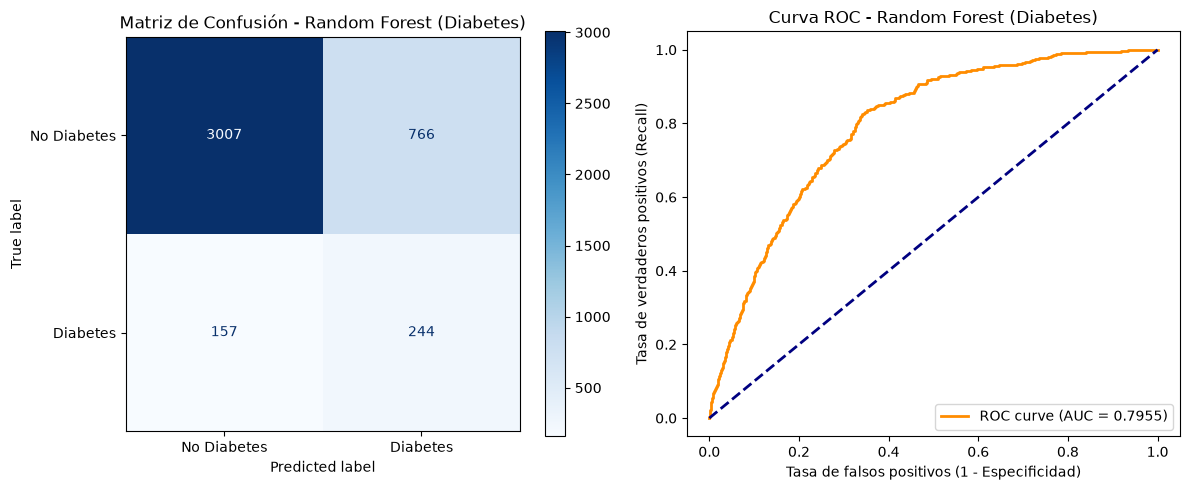

In [14]:
# ===========================================
# EVALUACIÓN RANDOM FOREST C/ PESOS DINÁMICOS
# ===========================================

# Predicciones 
y_pred_rf_subsample = rf_subsample.predict(X_test_diab)
y_proba_rf_subsample = rf_subsample.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - RF C/ PESOS DINÁMICOS")
print(classification_report(y_test_diab, y_pred_rf_subsample, digits=4))

# ROC-AUC 
auc_rf_subsample = roc_auc_score(y_test_diab, y_proba_rf_subsample)
print(f"ROC-AUC Score: {auc_rf_subsample:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf_subsample = confusion_matrix(y_test_diab, y_pred_rf_subsample)
disp_rf_subsample = ConfusionMatrixDisplay(confusion_matrix=cm_rf_subsample, display_labels=["No Diabetes", "Diabetes"])
disp_rf_subsample.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (Diabetes)")

# Curva ROC
fpr_rf_subsample, tpr_rf_subsample, _ = roc_curve(y_test_diab, y_proba_rf_subsample)
axes[1].plot(fpr_rf_subsample, tpr_rf_subsample, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_rf_subsample:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)
              precision    recall  f1-score   support

           0     0.9547    0.7935    0.8667      3773
           1     0.2495    0.6459    0.3600       401

    accuracy                         0.7793      4174
   macro avg     0.6021    0.7197    0.6133      4174
weighted avg     0.8870    0.7793    0.8180      4174

ROC-AUC Score: 0.8041


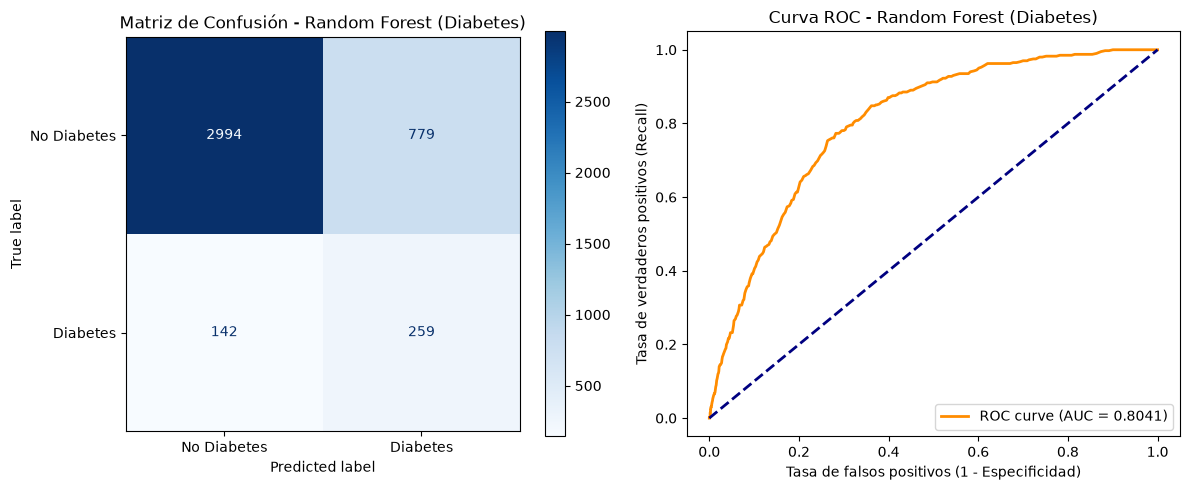

In [15]:
# ====================================
# EVALUACIÓN  BALANCED RANDOM FOREST 
# ====================================

# Predicciones 
y_pred_brf_diabetes = brf_diabetes.predict(X_test_diab)
y_proba_brf_diabetes = brf_diabetes.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diabetes, digits=4))

# ROC-AUC 
auc_brf_diabetes = roc_auc_score(y_test_diab, y_proba_brf_diabetes)
print(f"ROC-AUC Score: {auc_brf_diabetes:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diabetes = confusion_matrix(y_test_diab, y_pred_brf_diabetes)
disp_brf_diabetes = ConfusionMatrixDisplay(confusion_matrix=cm_brf_diabetes, display_labels=["No Diabetes", "Diabetes"])
disp_brf_diabetes.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Random Forest (Diabetes)")

# Curva ROC
fpr_brf_diabetes, tpr_brf_diabetes, _ = roc_curve(y_test_diab, y_proba_brf_diabetes)
axes[1].plot(fpr_brf_diabetes, tpr_brf_diabetes, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_brf_diabetes:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

,Umbral,Recall Diabetes,Precisión Diabetes,F1-Score,FN (Diabéticos No Detectados)
0,0.20,97.26%,13.05%,0.2301,10
1,0.25,95.26%,14.22%,0.2474,19
2,0.30,92.27%,15.42%,0.2643,30
3,0.35,90.02%,16.82%,0.2835,40
4,0.40,87.28%,18.07%,0.2994,50
5,0.45,83.79%,19.51%,0.3165,65
6,0.50,78.80%,20.98%,0.3314,85


INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO
              precision    recall  f1-score   support

           0     0.9681    0.6846    0.8020      3773
           1     0.2098    0.7880    0.3314       401

    accuracy                         0.6945      4174
   macro avg     0.5890    0.7363    0.5667      4174
weighted avg     0.8953    0.6945    0.7568      4174

ROC-AUC Score: 0.8031


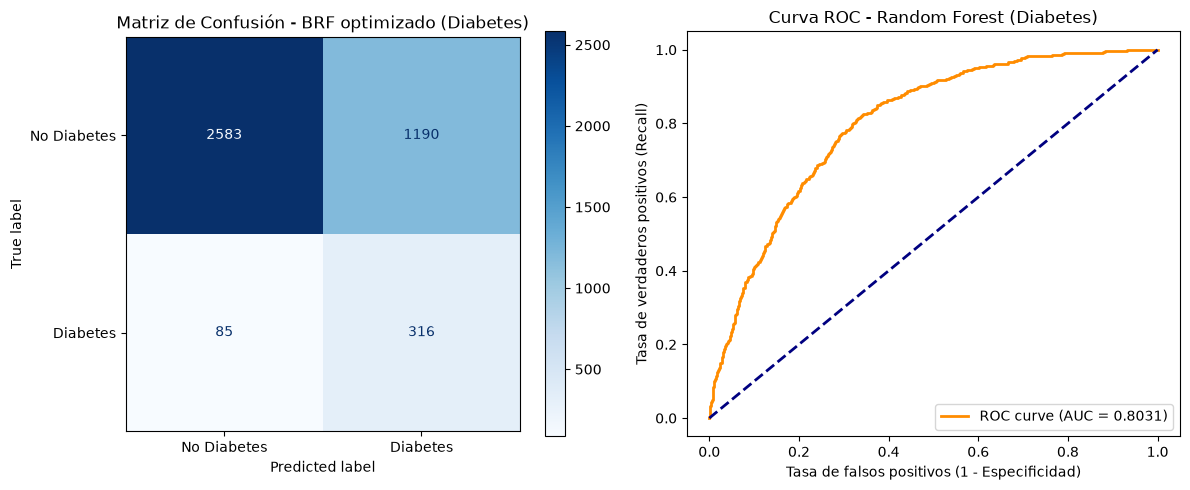

In [19]:
# =============================================
# EVALUACIÓN Balanced Random Forest optimizado 
# =============================================

# Predicciones 
y_pred_opt = brf_opt.predict(X_test_diab)
y_proba_opt = brf_opt.predict_proba(X_test_diab)[:, 1]

# 5. Barrido de Umbrales
umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
resultados = []

for u in umbrales:
    y_pred_u = (y_proba_opt >= u).astype(int)
    rep = classification_report(y_test_diab, y_pred_u, output_dict=True)

    resultados.append(
        {
            "Umbral": u,
            "Recall Diabetes": f"{rep['1']['recall']*100:.2f}%",
            "Precisión Diabetes": f"{rep['1']['precision']*100:.2f}%",
            "F1-Score": f"{rep['1']['f1-score']:.4f}",
            "FN (Diabéticos No Detectados)": int(
                (1 - rep["1"]["recall"]) * rep["1"]["support"]
            ),
        }
    )

df_umbrales = pd.DataFrame(resultados)
display(df_umbrales)

print("INFORME DE CLASIFICACIÓN - BALANCED RANDOM FOREST OPTIMIZADO")
print(classification_report(y_test_diab, y_pred_opt, digits=4))

# ROC-AUC 
auc_opt_diabetes = roc_auc_score(y_test_diab, y_proba_opt)
print(f"ROC-AUC Score: {auc_opt_diabetes:.4f}")

# Matriz de confusión 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_opt_diabetes = confusion_matrix(y_test_diab, y_pred_opt)
disp_opt_diabetes = ConfusionMatrixDisplay(confusion_matrix=cm_opt_diabetes, display_labels=["No Diabetes", "Diabetes"])
disp_opt_diabetes.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - BRF optimizado (Diabetes)")

# Curva ROC
fpr_opt_diabetes, tpr_opt_diabetes, _ = roc_curve(y_test_diab, y_proba_opt)
axes[1].plot(fpr_opt_diabetes, tpr_opt_diabetes, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_opt_diabetes:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)
              precision    recall  f1-score   support

           0     0.9611    0.7339    0.8323      3773
           1     0.2235    0.7207    0.3412       401

    accuracy                         0.7326      4174
   macro avg     0.5923    0.7273    0.5867      4174
weighted avg     0.8903    0.7326    0.7851      4174

ROC-AUC Score: 0.8022


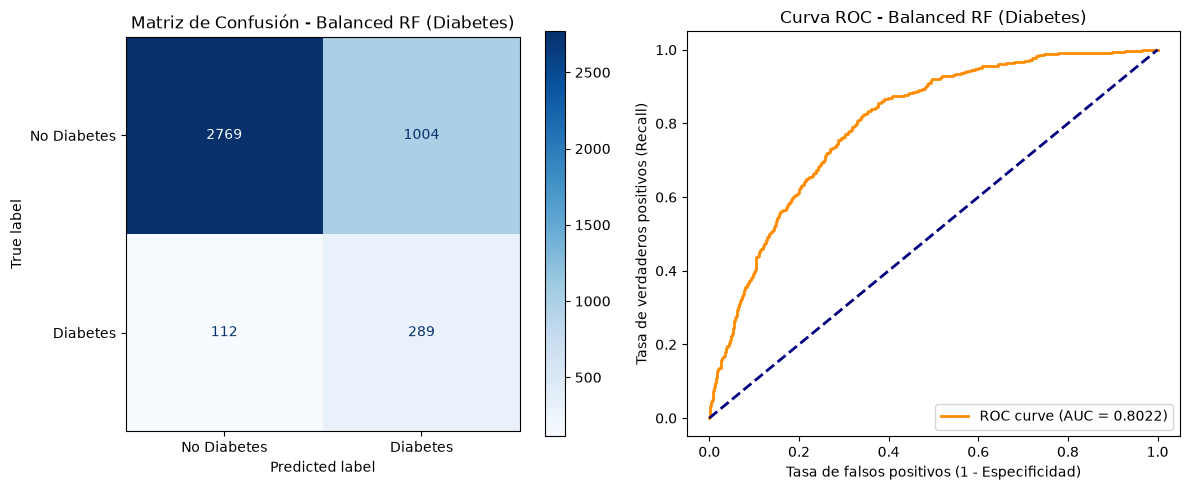

In [ ]:
# ==========================================================
# EVALUACIÓN BALANCED RANDOM FOREST OPTIMIZADO (DIABETES)
# ==========================================================

# Predicciones
y_pred_brf_diab = brf_diab_optimo.predict(X_test_diab)
y_proba_brf_diab = brf_diab_optimo.predict_proba(X_test_diab)[:, 1]

print("INFORME DE CLASIFICACIÓN - Balanced Random Forest (Diabetes)")
print(classification_report(y_test_diab, y_pred_brf_diab, digits=4))

# ROC-AUC
auc_brf_diab = roc_auc_score(y_test_diab, y_proba_brf_diab)
print(f"ROC-AUC Score: {auc_brf_diab:.4f}")

# Matriz de confusión + Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_brf_diab = confusion_matrix(y_test_diab, y_pred_brf_diab)
disp_brf_diab = ConfusionMatrixDisplay(
    confusion_matrix=cm_brf_diab,
    display_labels=["No Diabetes", "Diabetes"]
)
disp_brf_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - Balanced RF (Diabetes)")

fpr_brf_diab, tpr_brf_diab, _ = roc_curve(y_test_diab, y_proba_brf_diab)
axes[1].plot(fpr_brf_diab, tpr_brf_diab, color="darkorange", lw=2,
             label=f"ROC curve (AUC = {auc_brf_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Balanced RF (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

El modelo Balanced Random Forest Classifier optimizado (con max_depth=12, submuestreo nativo auto e incorporación de FACTORADULTO) demostró ser la arquitectura basada en ensambles más efectiva. A diferencia de las aproximaciones sintéticas como SMOTE, este enfoque eliminó el sesgo de la clase mayoritaria sin generar sobreajuste al ruido, alcanzando una sensibilidad (Recall) del 78.80% bajo el umbral estándar de 0.50 y hasta un 83.79% ajustando el umbral a 0.45. Estos resultados consolidan a Balanced Random Forest como una alternativa competitiva frente a la Regresión Logística en tareas de cribado epidemiológico.

# SVM

In [22]:
# Cargar datos

svm_diab_cw = joblib.load("../models/svm_hta_diab.joblib")
svm_diab = joblib.load("../models/svm_diab.joblib")
svm_diab_smote = joblib.load("../models/svm_diab_smote.joblib")


INFORME DE CLASIFICACIÓN - SVM (Diabetes)
              precision    recall  f1-score   support

           0     0.9559    0.7649    0.8498      3773
           1     0.2320    0.6683    0.3445       401

    accuracy                         0.7556      4174
   macro avg     0.5940    0.7166    0.5971      4174
weighted avg     0.8864    0.7556    0.8013      4174

ROC-AUC Score: 0.7914


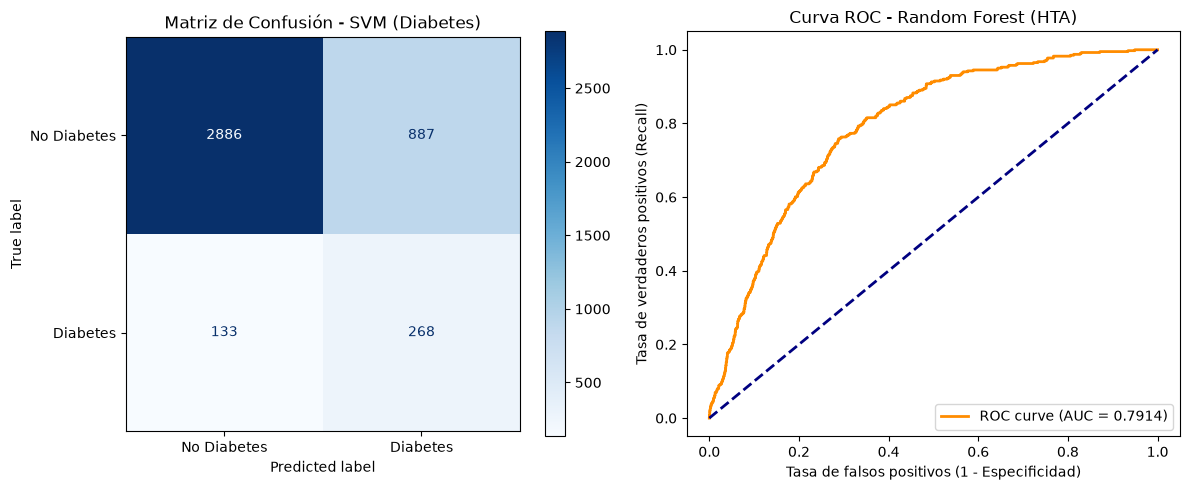

In [23]:
# =========================================
# EVALUACIÓN SVM 'class_weight' - DIABETES
# ==========================================

# Predicciones 
y_pred_svm_diab_cw = svm_diab_cw.predict(X_test_diab)
y_pred_proba_svm_diab_cw = svm_diab_cw.predict_proba(X_test_diab)[:, 1]



print("INFORME DE CLASIFICACIÓN - SVM (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_cw, digits=4))

# ROC-AUC
auc_svm_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_cw)
print(f"ROC-AUC Score: {auc_svm_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_cw = confusion_matrix(y_test_diab,y_pred_svm_diab_cw)
disp_svm_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (Diabetes)")

# CURVA ROC 
fpr_svm_diab_cw, tpr_svm_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_cw)
axes[1].plot(fpr_svm_diab_cw, tpr_svm_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_cw:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - SVM (Diabetes)
              precision    recall  f1-score   support

           0     0.9179    0.9329    0.9253      3773
           1     0.2537    0.2145    0.2324       401

    accuracy                         0.8639      4174
   macro avg     0.5858    0.5737    0.5789      4174
weighted avg     0.8541    0.8639    0.8588      4174

ROC-AUC Score: 0.7096


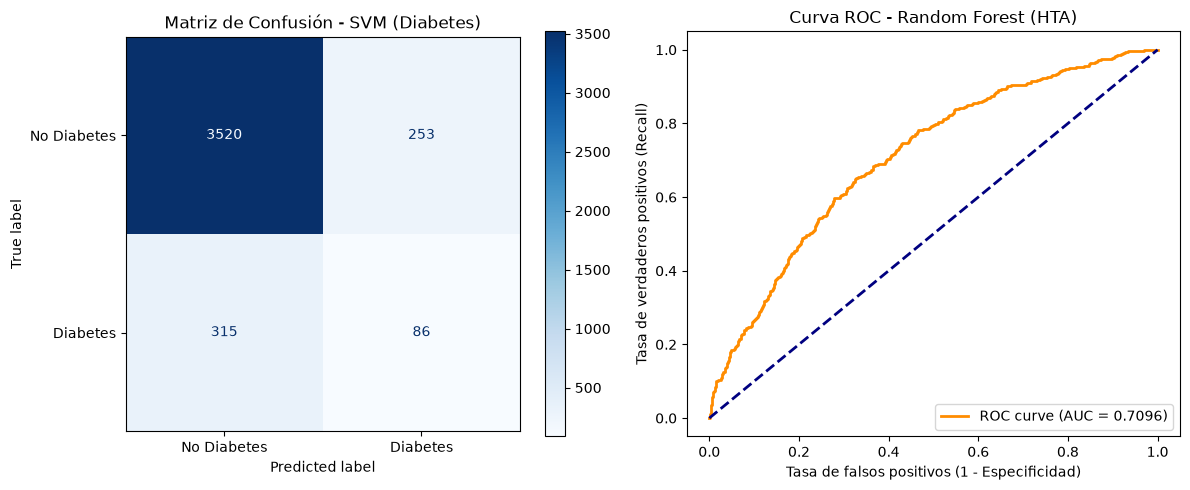

In [24]:
# =========================================================
# EVALUACIÓN SVM 'class_weight' + 'sample_weight'- DIABETES
# =========================================================

# Predicciones 
y_pred_svm_diab = svm_diab.predict(X_test_diab)
y_pred_proba_svm_diab = svm_diab.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab, digits=4))

# ROC-AUC
auc_svm_diab = roc_auc_score(y_test_diab, y_pred_proba_svm_diab)
print(f"ROC-AUC Score: {auc_svm_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab = confusion_matrix(y_test_diab,y_pred_svm_diab)
disp_svm_diab = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (Diabetes)")

# CURVA ROC 
fpr_svm_diab, tpr_svm_diab, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab)
axes[1].plot(fpr_svm_diab, tpr_svm_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9374    0.8579    0.8959      3773
           1     0.2566    0.4613    0.3298       401

    accuracy                         0.8198      4174
   macro avg     0.5970    0.6596    0.6128      4174
weighted avg     0.8720    0.8198    0.8415      4174

ROC-AUC Score: 0.7650


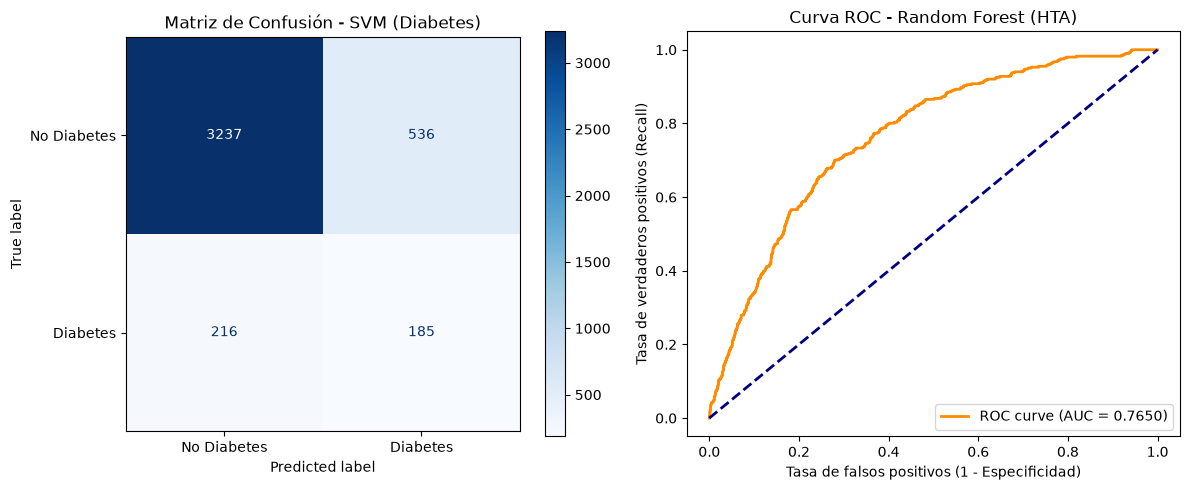

In [25]:
# ====================================
# EVALUACIÓN SVM CON SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichas
y_pred_svm_diab_smote = svm_diab_smote.predict(X_test_diab)
y_pred_proba_svm_diab_smote = svm_diab_smote.predict_proba(X_test_diab)[:, 1]


print("INFORME DE CLASIFICACIÓN - SVM CON SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_svm_diab_smote, digits=4))

# ROC-AUC
auc_svm_diab_smote = roc_auc_score(y_test_diab, y_pred_proba_svm_diab_smote)
print(f"ROC-AUC Score: {auc_svm_diab_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_svm_diab_smote = confusion_matrix(y_test_diab,y_pred_svm_diab_smote)
disp_svm_diab_smote = ConfusionMatrixDisplay(confusion_matrix=cm_svm_diab_smote, display_labels=["No Diabetes", "Diabetes"])
disp_svm_diab_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - SVM (Diabetes)")

# CURVA ROC 
fpr_svm_diab_smote, tpr_svm_diab_smote, _ = roc_curve(y_test_diab, y_pred_proba_svm_diab_smote)
axes[1].plot(fpr_svm_diab_smote, tpr_svm_diab_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_svm_diab_smote:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - Random Forest (HTA)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

# EVALUACIÓN MODELOS XGBOOST

In [26]:
# CARGAR DATOS
xgb_model_cw_diab = joblib.load("../models/xgb_model_cw_diab.joblib")
xgb_model_diab = joblib.load("../models/xgb_model_diab.joblib")
xgb_model_smote_diab = joblib.load("../models/xgb_model_smote_diab.joblib")

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)
              precision    recall  f1-score   support

           0     0.9517    0.7779    0.8561      3773
           1     0.2312    0.6284    0.3380       401

    accuracy                         0.7635      4174
   macro avg     0.5914    0.7032    0.5970      4174
weighted avg     0.8825    0.7635    0.8063      4174

ROC-AUC Score: 0.7975


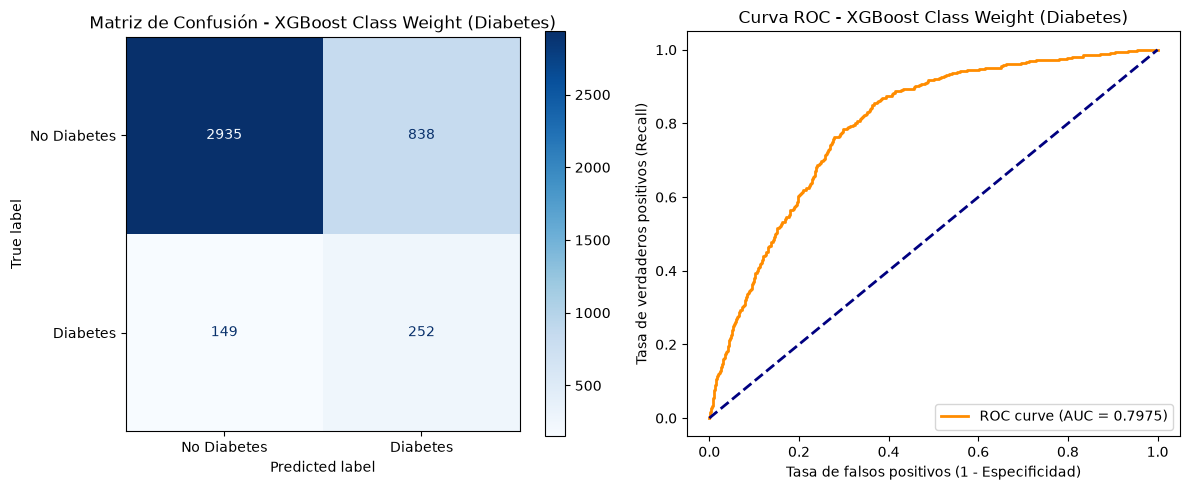

In [27]:
# ===============================================
# EVALUACIÓN XGBOOST 'class_weight' - DIABETES
# ===============================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab_cw = xgb_model_cw_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab_cw = xgb_model_cw_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab_cw, digits=4))

# ROC-AUC
auc_xgb_diab_cw = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab_cw)
print(f"ROC-AUC Score: {auc_xgb_diab_cw:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab_cw = confusion_matrix(y_test_diab, y_pred_xgb_diab_cw)
disp_xgb_diab_cw = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab_cw, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab_cw.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Class Weight (Diabetes)")

# Curva ROC
fpr_xgb_diab_cw, tpr_xgb_diab_cw, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab_cw)
axes[1].plot(fpr_xgb_diab_cw, tpr_xgb_diab_cw, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab_cw:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Class Weight (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (Diabetes)
              precision    recall  f1-score   support

           0     0.9512    0.7949    0.8660      3773
           1     0.2419    0.6160    0.3474       401

    accuracy                         0.7777      4174
   macro avg     0.5965    0.7054    0.6067      4174
weighted avg     0.8830    0.7777    0.8162      4174

ROC-AUC Score: 0.7933


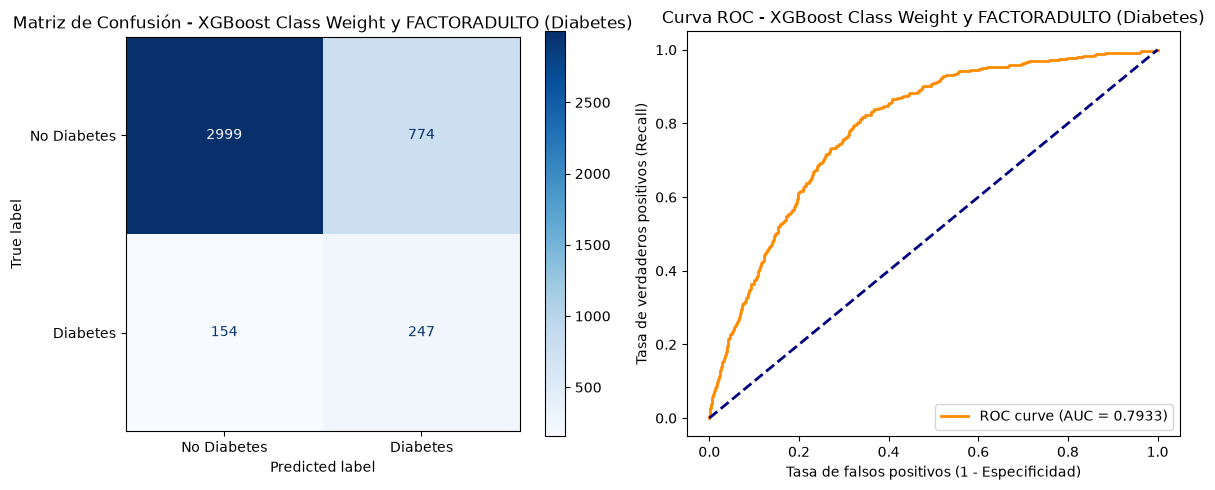

In [28]:
# ===========================================================
# EVALUACIÓN XGBOOST 'class_weight' y FACTORADULTO - DIABETES
# ===========================================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_diab = xgb_model_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_diab = xgb_model_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST CLASS WEIGHT y FACTORADULTO (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_diab, digits=4))

# ROC-AUC
auc_xgb_diab = roc_auc_score(y_test_diab, y_pred_proba_xgb_diab)
print(f"ROC-AUC Score: {auc_xgb_diab:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_diab = confusion_matrix(y_test_diab, y_pred_xgb_diab)
disp_xgb_diab = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_diab, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_diab.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost Class Weight y FACTORADULTO (Diabetes)")

# Curva ROC
fpr_xgb_diab, tpr_xgb_diab, _ = roc_curve(y_test_diab, y_pred_proba_xgb_diab)
axes[1].plot(fpr_xgb_diab, tpr_xgb_diab, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_diab:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost Class Weight y FACTORADULTO (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)
              precision    recall  f1-score   support

           0     0.9102    0.9809    0.9443      3773
           1     0.3333    0.0898    0.1415       401

    accuracy                         0.8953      4174
   macro avg     0.6218    0.5353    0.5429      4174
weighted avg     0.8548    0.8953    0.8671      4174

ROC-AUC Score: 0.8113


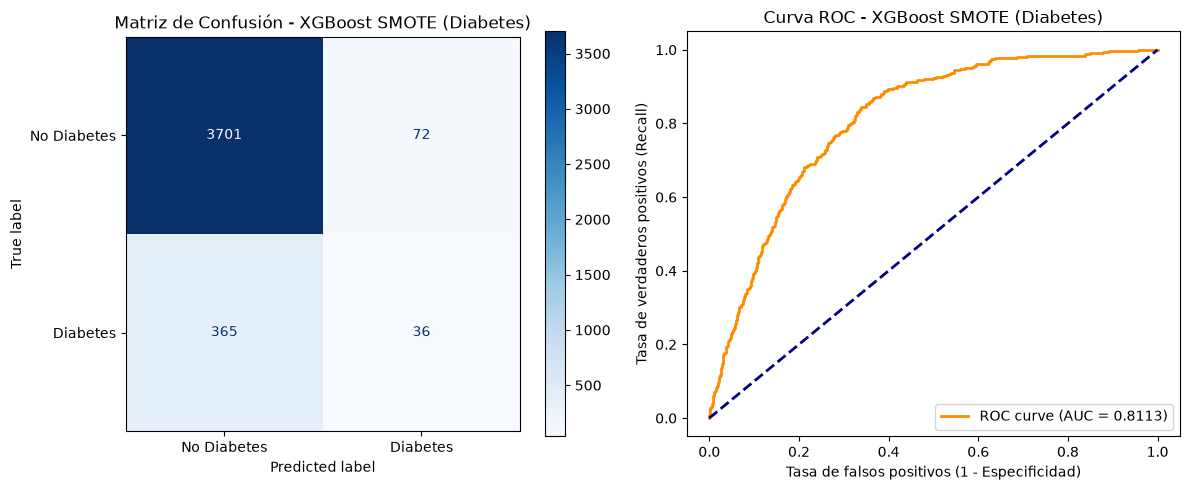

In [29]:
# ====================================
# EVALUACIÓN XGBOOST SMOTE - DIABETES
# ====================================

# Predicciones y probabilidades predichass
y_pred_proba_xgb_smote = xgb_model_smote_diab.predict_proba(X_test_diab)[:, 1]
y_pred_xgb_smote = xgb_model_smote_diab.predict(X_test_diab)


print("INFORME DE CLASIFICACIÓN - XGBOOST SMOTE (Diabetes)")
print(classification_report(y_test_diab, y_pred_xgb_smote, digits=4))

# ROC-AUC
auc_xgb_smote = roc_auc_score(y_test_diab, y_pred_proba_xgb_smote)
print(f"ROC-AUC Score: {auc_xgb_smote:.4f}")

# MATRIZ DE CONFUSIÓN 
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_xgb_smote = confusion_matrix(y_test_diab, y_pred_xgb_smote)
disp_xgb_smote= ConfusionMatrixDisplay(confusion_matrix=cm_xgb_smote, display_labels=["No Diabetes", "Diabetes"])
disp_xgb_smote.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Matriz de Confusión - XGBoost SMOTE (Diabetes)")

# Curva ROC
fpr_xgb_smote, tpr_xgb_smote, _ = roc_curve(y_test_diab, y_pred_proba_xgb_smote)
axes[1].plot(fpr_xgb_smote, tpr_xgb_smote, color="darkorange", lw=2, label=f"ROC curve (AUC = {auc_xgb_smote:.4f})",)
axes[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
axes[1].set_xlabel("Tasa de falsos positivos (1 - Especificidad)")
axes[1].set_ylabel("Tasa de verdaderos positivos (Recall)")
axes[1].set_title("Curva ROC - XGBoost SMOTE (Diabetes)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()